# How to use Pandas

We are going through this again. Lovely.

In [1]:
#importando pandas
import pandas as pd

## Ingresar y visualizar datos

Un dataframe es una tabla, en resumen. Una forma menos normal de llamarlo es como un *conjunto de datos bidimensional*.

Por otro lado, las series son listas de datos unidimensionales. Los dataframes, las columnas de los dataframes, son considerados series.

In [2]:
tabla = pd.DataFrame(
    {
        'Nombre': ['Juan', 'Pedro', 'María', 'Laura'],
        'Edad': [35, 41, 28, 66],
        'País':['México', 'España', 'Perú', 'Argentina'],
        'Automóvil':['No','Sí','Sí','No']
    }
)

tabla

,Nombre,Edad,País,Automóvil
0,Juan,35,México,No
1,Pedro,41,España,Sí
2,María,28,Perú,Sí
3,Laura,66,Argentina,No


In [3]:
tabla['Nombre']

0     Juan
1    Pedro
2    María
3    Laura
Name: Nombre, dtype: object

In [4]:
tabla[['Nombre','País']]

,Nombre,País
0,Juan,México
1,Pedro,España
2,María,Perú
3,Laura,Argentina


In [5]:
type(tabla)

pandas.core.frame.DataFrame

In [6]:
type(tabla['Nombre'])

pandas.core.series.Series

Vamos a abrir un archivo, "VentasPorProveedor.csv". Este archivo tiene dos problemas que tenemos que aclarar como parámetros en la función:
- Está separado por puntos y comas
- Las primeros cinco filas no aportan nada al dataframe

Es por eso que utilizamos la función `read_csv()` agregando los parámetros `sep=` y `skiprows=`.

In [7]:
df = pd.read_csv('VentasPorProveedor.csv', sep=";", skiprows=5)

In [8]:
df.head()

,Fecha,Vendedor,Región,Artículo,Categoría,Unidades,Ganancia
0,1/1/2016,Steve Ashton,Norte,Medias Femeninas,Vestimenta,6,"18,00"
1,1/1/2016,Trevor Snodgrass,Oeste,Chocolate,Comestibles,8,"3,84"
2,1/1/2016,Sarah Bond,Sur,Gorras,Vestimenta,3,"6,30"
3,1/1/2016,Desmond Delaney,Sur,Sánguche de Queso,Comestibles,9,"14,40"
4,1/1/2016,Desmond Delaney,Este,Chocolate,Comestibles,14,"6,72"


Podemos ver qué tan grande es el dataframe, las dimensiones del dataframe, checando el atributo `shape`. Este devuelve una tupla, un par de valores que dice las filas y columnas que contiene el dataframe respectivamente.

In [9]:
df.shape

(460, 7)

In [10]:
print(f"Filas: {df.shape[0]} \nColumnas: {df.shape[1]}")

Filas: 460 
Columnas: 7


In [11]:
df.head() # para tener las primeras cinco filas
df.tail() # para tener las últimas cinco filas

,Fecha,Vendedor,Región,Artículo,Categoría,Unidades,Ganancia
455,31/1/2016,Sarah Bond,Sur,Bufanda,Vestimenta,6,"16,50"
456,31/1/2016,Dustin Gee,Este,Sandalias,Vestimenta,11,"115,50"
457,31/1/2016,Dustin Gee,Este,Sánguche de Queso,Comestibles,4,"6,40"
458,31/1/2016,Dustin Gee,Norte,Escobillón,Hogar,8,"6,80"
459,31/1/2016,Trevor Snodgrass,Sur,Pepinillo,Comestibles,7,"2,10"


Está el método `info()` para tener información del dataframe, como tipo de datos, nombre de series, datos nulos presentes, entre otros.

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 460 entries, 0 to 459
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Fecha      460 non-null    object
 1   Vendedor   460 non-null    object
 2   Región     460 non-null    object
 3   Artículo   460 non-null    object
 4   Categoría  460 non-null    object
 5   Unidades   460 non-null    int64 
 6   Ganancia   460 non-null    object
dtypes: int64(1), object(6)
memory usage: 25.3+ KB


## Análisis de datos

Tenemos una función, `value_counts()`, particularmente útil para contar valores. Este método devuelve un objeto de tipo serie, contando todos los valores únicos dentro del dataframe. Los elementos están ordenados desde el más frecuente al menos frecuente por defecto.
Puede ser ordenado ascendentemente utilizando el parámetro `ascending=` y también se pueden observar valores "nulos" con `dropna=` seteado en falso, pues está activado por defecto.

In [13]:
df['Vendedor'].value_counts()

Vendedor
Sarah Bond          86
Steve Ashton        84
Desmond Delaney     76
Trevor Snodgrass    75
Dustin Gee          70
Boris Stanford      69
Name: count, dtype: int64

In [14]:
df['Región'].value_counts(ascending=True, dropna=False)

Región
Norte    100
Oeste    102
Sur      120
Este     138
Name: count, dtype: int64

Se pueden ordenar los valores usando el método `sort_values()`. Puede ser usado en series individuales, o con dataframes enteros.

In [15]:
df['Vendedor'].sort_values()

198      Boris Stanford
71       Boris Stanford
66       Boris Stanford
259      Boris Stanford
64       Boris Stanford
             ...       
212    Trevor Snodgrass
209    Trevor Snodgrass
206    Trevor Snodgrass
286    Trevor Snodgrass
459    Trevor Snodgrass
Name: Vendedor, Length: 460, dtype: object

In [16]:
df.sort_values(by=['Vendedor', 'Ganancia'])

,Fecha,Vendedor,Región,Artículo,Categoría,Unidades,Ganancia
93,6/1/2016,Boris Stanford,Norte,Chocolate,Comestibles,2,"0,96"
450,31/1/2016,Boris Stanford,Este,Chocolate,Comestibles,3,"1,44"
259,18/1/2016,Boris Stanford,Sur,Pepinillo,Comestibles,5,"1,50"
25,2/1/2016,Boris Stanford,Este,Pan,Comestibles,4,"1,60"
64,5/1/2016,Boris Stanford,Sur,Pan,Comestibles,4,"1,60"
...,...,...,...,...,...,...,...
231,15/1/2016,Trevor Snodgrass,Este,Gorras,Vestimenta,4,"8,40"
314,21/1/2016,Trevor Snodgrass,Oeste,Bombilla,Hogar,14,"8,40"
328,22/1/2016,Trevor Snodgrass,Oeste,Bombilla,Hogar,14,"8,40"
69,5/1/2016,Trevor Snodgrass,Norte,Calcetines,Vestimenta,4,"9,00"


Se pueden usar condiciones booleanas para filtrar información.

In [17]:
df['Artículo'] == 'Gorras' # Ugly

0      False
1      False
2       True
3      False
4      False
       ...  
455    False
456    False
457    False
458    False
459    False
Name: Artículo, Length: 460, dtype: bool

In [18]:
df[df['Artículo'] == 'Gorras'] # Pretty

,Fecha,Vendedor,Región,Artículo,Categoría,Unidades,Ganancia
2,1/1/2016,Sarah Bond,Sur,Gorras,Vestimenta,3,"6,30"
7,1/1/2016,Steve Ashton,Oeste,Gorras,Vestimenta,2,"4,20"
38,4/1/2016,Steve Ashton,Oeste,Gorras,Vestimenta,13,"27,30"
57,4/1/2016,Dustin Gee,Este,Gorras,Vestimenta,2,"4,20"
85,6/1/2016,Sarah Bond,Norte,Gorras,Vestimenta,9,"18,90"
156,10/1/2016,Trevor Snodgrass,Norte,Gorras,Vestimenta,7,"14,70"
159,11/1/2016,Steve Ashton,Norte,Gorras,Vestimenta,2,"4,20"
170,11/1/2016,Sarah Bond,Este,Gorras,Vestimenta,9,"18,90"
186,12/1/2016,Sarah Bond,Este,Gorras,Vestimenta,11,"23,10"
187,12/1/2016,Dustin Gee,Sur,Gorras,Vestimenta,13,"27,30"


In [19]:
# Usando operadores booleanos...
df[
    (df['Artículo'] == 'Gorras') & # or es |
    (df['Región'] == 'Norte')
]

,Fecha,Vendedor,Región,Artículo,Categoría,Unidades,Ganancia
85,6/1/2016,Sarah Bond,Norte,Gorras,Vestimenta,9,"18,90"
156,10/1/2016,Trevor Snodgrass,Norte,Gorras,Vestimenta,7,"14,70"
159,11/1/2016,Steve Ashton,Norte,Gorras,Vestimenta,2,"4,20"
201,14/1/2016,Desmond Delaney,Norte,Gorras,Vestimenta,5,"10,50"
360,25/1/2016,Steve Ashton,Norte,Gorras,Vestimenta,7,"14,70"
368,26/1/2016,Boris Stanford,Norte,Gorras,Vestimenta,7,"14,70"
394,27/1/2016,Steve Ashton,Norte,Gorras,Vestimenta,14,"29,40"
396,27/1/2016,Trevor Snodgrass,Norte,Gorras,Vestimenta,3,"6,30"


Para filtrar datos en un dataframe, podemos utilizar `str.metodo()` para trabajar con strings.

In [20]:
df['Vendedor'].str.contains('Trevor') # Ugly

0      False
1       True
2      False
3      False
4      False
       ...  
455    False
456    False
457    False
458    False
459     True
Name: Vendedor, Length: 460, dtype: bool

In [21]:
df[df['Vendedor'].str.contains('Trevor')] # Pretty

,Fecha,Vendedor,Región,Artículo,Categoría,Unidades,Ganancia
1,1/1/2016,Trevor Snodgrass,Oeste,Chocolate,Comestibles,8,"3,84"
5,1/1/2016,Trevor Snodgrass,Este,Cerveza,Comestibles,15,"6,00"
8,1/1/2016,Trevor Snodgrass,Este,Pan,Comestibles,12,"4,80"
10,1/1/2016,Trevor Snodgrass,Sur,Pan,Comestibles,6,"2,40"
12,1/1/2016,Trevor Snodgrass,Sur,Shorts,Vestimenta,6,"29,40"
...,...,...,...,...,...,...,...
437,30/1/2016,Trevor Snodgrass,Este,Calcetines,Vestimenta,10,"22,50"
440,30/1/2016,Trevor Snodgrass,Este,Gorras,Vestimenta,6,"12,60"
442,31/1/2016,Trevor Snodgrass,Este,Sandalias,Vestimenta,6,"63,00"
446,31/1/2016,Trevor Snodgrass,Oeste,Sudadera,Vestimenta,2,"12,00"


In [22]:
df[df['Vendedor'].str.startswith('T')]

,Fecha,Vendedor,Región,Artículo,Categoría,Unidades,Ganancia
1,1/1/2016,Trevor Snodgrass,Oeste,Chocolate,Comestibles,8,"3,84"
5,1/1/2016,Trevor Snodgrass,Este,Cerveza,Comestibles,15,"6,00"
8,1/1/2016,Trevor Snodgrass,Este,Pan,Comestibles,12,"4,80"
10,1/1/2016,Trevor Snodgrass,Sur,Pan,Comestibles,6,"2,40"
12,1/1/2016,Trevor Snodgrass,Sur,Shorts,Vestimenta,6,"29,40"
...,...,...,...,...,...,...,...
437,30/1/2016,Trevor Snodgrass,Este,Calcetines,Vestimenta,10,"22,50"
440,30/1/2016,Trevor Snodgrass,Este,Gorras,Vestimenta,6,"12,60"
442,31/1/2016,Trevor Snodgrass,Este,Sandalias,Vestimenta,6,"63,00"
446,31/1/2016,Trevor Snodgrass,Oeste,Sudadera,Vestimenta,2,"12,00"


## Gráficos Básicos

Usaremos `matplotlib.pyplot` para realizar visualizaciones de gráficos

In [23]:
import matplotlib.pyplot as plt

### The basics

Inicialmente, se tiene el método `plot()`, que se usa con variables que guardan objetos `pandas.DataFrame`. Sin ningún argumento, lo que hará es generar un gráfico de líneas; sin embargo, con el parámetro `kind` se puede definir gráficos de casi cualquier tipo, siendo ejemplos:

- `kind=bar` para gráficos de barra
- `kind=pie` para gráficos de pastel
- `kind=barh` para gráficos de barra horizontales
- `kind=scatter` para diagramas de dispersión

In [24]:
food = df[df['Categoría'] == 'Comestibles']
food = food['Artículo'].value_counts()
food

Artículo
Pan                  26
Sánguche de Queso    25
Chocolate            25
Pepinillo            24
Soda                 19
Cerveza              17
Caramelos            17
Name: count, dtype: int64

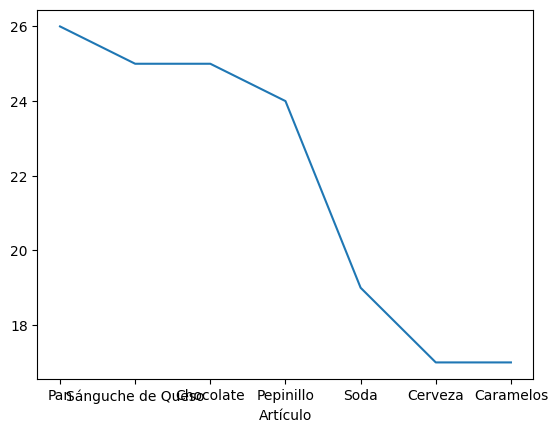

In [ ]:
food.plot(kind='line'); 

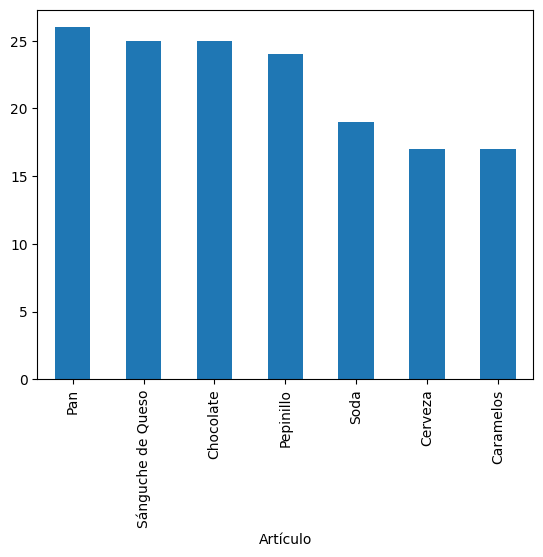

In [26]:
food.plot(kind='bar'); # gráfico de barras

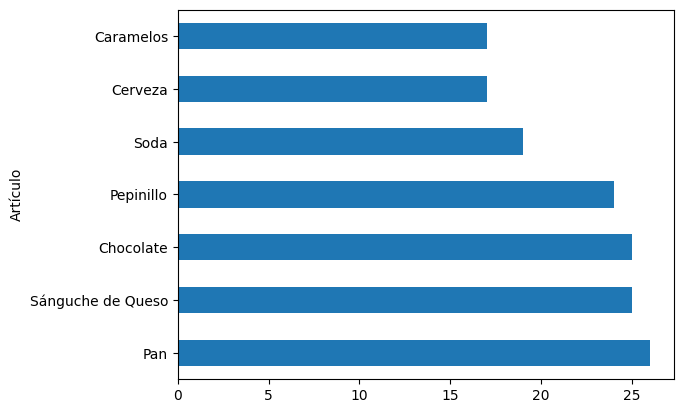

In [27]:
food.plot(kind='barh'); # gráfico de barras horizontales

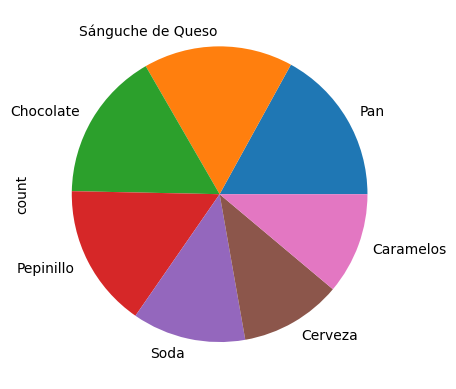

In [28]:
food.plot(kind='pie'); # gráfico de pastel

In [29]:
# gráfico de dispersión
df['Ganancia'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 460 entries, 0 to 459
Series name: Ganancia
Non-Null Count  Dtype 
--------------  ----- 
460 non-null    object
dtypes: object(1)
memory usage: 3.7+ KB


In [30]:
# MALDITA SEA, LOS NÚMEROS DE GANANCIA USAN COMA EN VEZ DE PUNTO.
# LOS MALDIGO GENTE DE EUROPA
df['Ganancia'] = df['Ganancia'].str.replace(",", ".", regex=False)
df['Ganancia'] = pd.to_numeric(df['Ganancia'], errors='raise')
df['Ganancia'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 460 entries, 0 to 459
Series name: Ganancia
Non-Null Count  Dtype  
--------------  -----  
460 non-null    float64
dtypes: float64(1)
memory usage: 3.7 KB


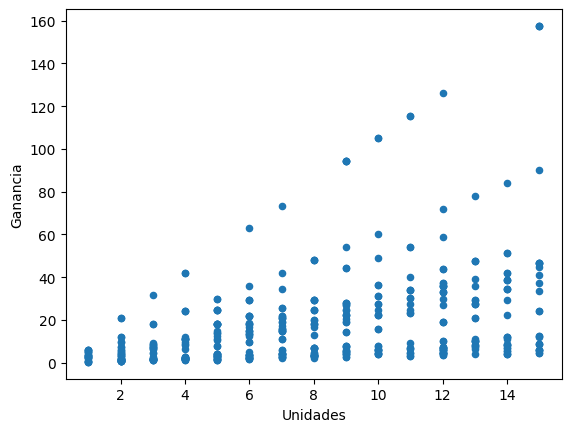

In [35]:
# Gráfico de dispersión, ahora sí
df.plot(kind='scatter', x="Unidades", y="Ganancia"); 

### Making stuff pretty

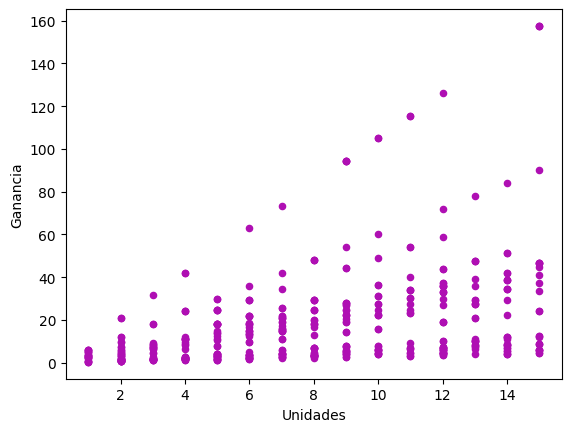

In [36]:
df.plot(kind='scatter', x="Unidades", y="Ganancia", color='#af0fb3'); 

#### Colormaps

Los mapas de colores son una forma de trabajar con muchos colores. Además de los arreglos de colores, hay que considerar los diferentes tipos de mapeos de colores:

- Secuecial: En el que los colores están organizados para que sigan una secuencia de menor a mayor, generalmente variando la iluminación de un mismo tono para marcar valores elevados y valores menores en un rango.
- Divergente: En el que los colores tienden a un color u a otro dependiendo de cuánto se alejan de un valor central, ya sea por defecto o por exceso.
- Cíclico: El último color también es el primero. Se suele usar con gradientes de colores que convergen en el final para marcar valores cíclicos.
- Cualitativo: Los colores no tienen ninguna relación entre sí.

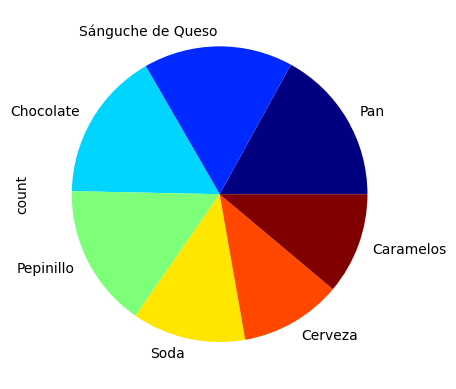

In [40]:
food.plot(kind='pie', colormap='jet'); 

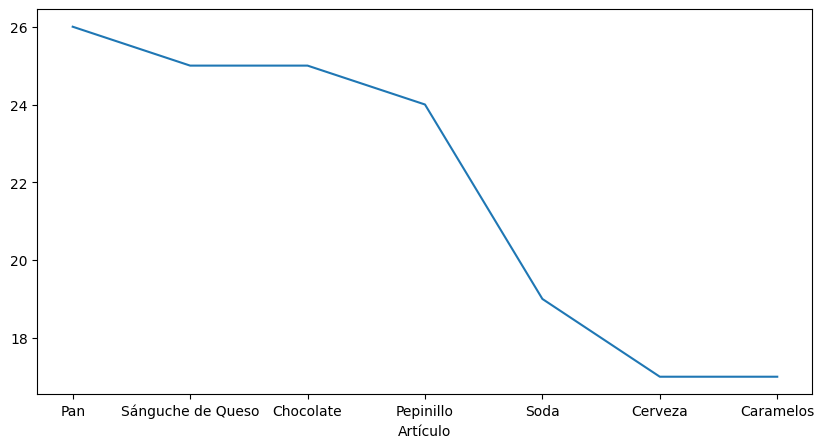

In [41]:
food.plot(kind='line', figsize=(10, 5)); 

## An actual matplotplib tutorial

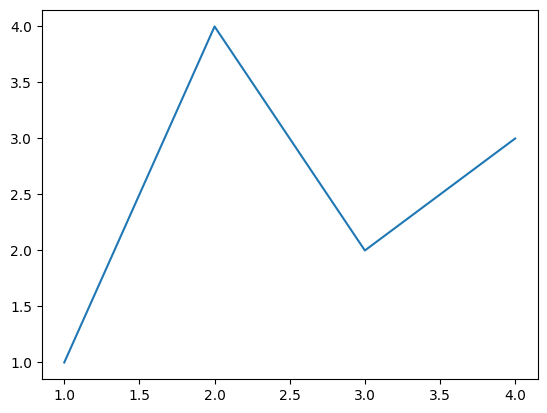

In [42]:
fig, ax = plt.subplots()
ax.plot([1, 2, 3, 4], [1, 4, 2, 3])
plt.show()

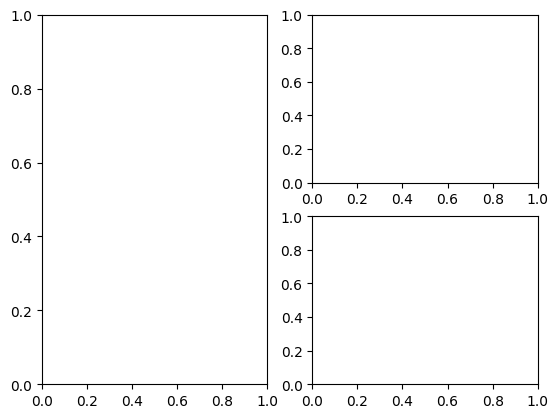

In [ ]:
# fig es el lienzo en el que se trabajan con los ejes.
# axs son los ejes dentro de la figura
fig, axs = plt.subplot_mosaic([['left', 'right_top'],
                               ['left', 'right_bottom']])
plt.show()